In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
DATA_RAW = Path("../data/raw")


train_path = DATA_RAW / "application_train.csv"
desc_path = DATA_RAW / "HomeCredit_columns_description.csv"

print(f"{train_path.exists()}")

df_train = pd.read_csv(train_path)
print(f"Kích thước tập train: {df_train.shape}")

True
Kích thước tập train: (307511, 122)


In [3]:
df_train.head(n = 5)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
desc_path = Path("../data/raw/HomeCredit_columns_description.csv")
df_desc = pd.read_csv(desc_path, encoding='latin1', index_col=0)

pd.set_option('display.max_colwidth', None)
df_desc.head(10)

,Table,Row,Description,Special
1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
2,application_{train|test}.csv,TARGET,"Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)",NaN
5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN
8,application_{train|test}.csv,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
9,application_{train|test}.csv,CNT_CHILDREN,Number of children the client has,NaN
10,application_{train|test}.csv,AMT_INCOME_TOTAL,Income of the client,NaN
11,application_{train|test}.csv,AMT_CREDIT,Credit amount of the loan,NaN
12,application_{train|test}.csv,AMT_ANNUITY,Loan annuity,NaN


In [5]:
def explain(col_name):
    """Hàm tra cứu nhanh ý nghĩa cột bất kỳ trong project"""
    result = df_desc[df_desc['Row'].str.contains(col_name, case=False, na=False)]
    if result.empty:
        print(f"Không tìm thấy cột nào chứa từ khóa: '{col_name}'")
    else:
        return result[['Table', 'Row', 'Description']]
    

In [6]:
df_train.columns

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='str', length=122)

In [7]:
explain('AMT_CREDIT') # Số khoảng co thể vay được
explain("EXT_SOURCE_1")
explain("EXT_SOURCE_2")



,Table,Row,Description
45,application_{train|test}.csv,EXT_SOURCE_2,Normalized score from external data source


In [8]:
import sweetviz as sv
import pandas as pd

df_sample = pd.read_csv("../data/raw/application_train.csv", nrows=20000)

report = sv.analyze(df_sample, target_feat="TARGET")

report.show_html("eda_report.html", open_browser=False)

                                             |          | [  0%]   00:00 -> (? left)

d:\anaconda\Lib\site-packages\sweetviz\graph_associations.py:219: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  new_dataframe[feature] = pd.Series(dtype=float)
d:\anaconda\Lib\site-packages\sweetviz\graph_associations.py:219: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  new_dataframe[feature] = pd.Series(dtype=float)
d:\anaconda\Lib\site-packages\sweetviz\graph_associations.py:219: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  C

Report eda_report.html was generated.


## 1. Sàng lọc khách quan trên toàn bộ 120 cột thô

Trước khi đi sâu vào bất kỳ nhóm biến nào, ta quét toàn bộ `120` cột của `application_train.csv` bằng các tiêu chí định lượng: tỷ lệ missing, độ tập trung giá trị (near-constant), trùng lặp nhóm `_MEDI/_MODE`, kiểm định `KS`/`Chi-square` và `IV`.

In [9]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import CATEGORICAL_COLS, DATA_PROCESSED_DIR, NUMERICAL_COLS, TARGET_COL
from src.eda_stats import (
    compute_chi2_tests,
    compute_ks_tests,
    screen_raw_features,
    summarize_statistical_tests,
)
from src.preprocess import engineer_features
from src.woe import WoEEncoder

df_screen = screen_raw_features(df_train)
print("=== TỔNG QUAN PHỄU LỌC 120 CỘT THÔ ===")
print(df_screen["screening_status"].value_counts().to_string())

print("\n=== CÁC BIẾN ỨNG VIÊN VƯỢT QUA PHỄU LỌC (xếp theo IV) ===")
candidates = df_screen[df_screen["screening_status"].str.startswith("Candidate")]
display(
    candidates[
        ["feature", "test_type", "stat", "effect_size", "p_adj", "missing_rate_%", "iv", "screening_status"]
    ].round({"stat": 4, "effect_size": 4, "missing_rate_%": 2, "iv": 4})
)

=== TỔNG QUAN PHỄU LỌC 120 CỘT THÔ ===
screening_status
Drop: Low IV (<0.02)                   31
Candidate (IV >= 0.02)                 25
Drop: Redundant (_MEDI/_MODE)          22
Drop: Near-constant (>=99%)            18
Drop: Missing > 60%                    17
Candidate (Missing 50-60%, High IV)     7

=== CÁC BIẾN ỨNG VIÊN VƯỢT QUA PHỄU LỌC (xếp theo IV) ===


,feature,test_type,stat,effect_size,p_adj,missing_rate_%,iv,screening_status
0,EXT_SOURCE_3,KS (2-sample),0.2698,0.2698,0.000000e+00,19.83,0.3171,Candidate (IV >= 0.02)
1,EXT_SOURCE_2,KS (2-sample),0.2237,0.2237,0.000000e+00,0.21,0.2975,Candidate (IV >= 0.02)
2,EXT_SOURCE_1,KS (2-sample),0.2427,0.2427,0.000000e+00,56.38,0.1418,"Candidate (Missing 50-60%, High IV)"
3,DAYS_EMPLOYED,KS (2-sample),0.0866,0.0866,2.690520e-148,0.00,0.1098,Candidate (IV >= 0.02)
4,DAYS_BIRTH,KS (2-sample),0.1219,0.1219,1.471172e-294,0.00,0.0839,Candidate (IV >= 0.02)
5,AMT_GOODS_PRICE,KS (2-sample),0.0942,0.0942,1.194897e-175,0.09,0.0805,Candidate (IV >= 0.02)
6,OCCUPATION_TYPE,Chi-square,1975.0828,0.0801,0.000000e+00,31.35,0.0759,Candidate (IV >= 0.02)
7,NAME_INCOME_TYPE,Chi-square,1227.9909,0.0632,2.334136e-263,0.00,0.0579,Candidate (IV >= 0.02)
8,ORGANIZATION_TYPE,Chi-square,1595.8963,0.0720,1.518255e-301,0.00,0.0578,Candidate (IV >= 0.02)
9,AMT_CREDIT,KS (2-sample),0.0695,0.0695,1.989616e-95,0.00,0.0526,Candidate (IV >= 0.02)


### Quyết định chốt 21 cột thô từ bảng sàng lọc
- **Loại bỏ tự động:** các cột missing `> 60%`, cột gần như hằng số (`>= 99%`, gồm đa số `FLAG_DOCUMENT_*` và `FLAG_MOBIL`), và cụm `_MEDI/_MODE` trùng thông tin với `_AVG`.
- **Ngoại lệ giữ lại:** `EXT_SOURCE_1` thiếu `56.38%` nhưng có `IV = 0.1554` (rất mạnh khi có giá trị) $\to$ giữ lại để tách bin `"Missing"`.
- **Lọc theo ngữ cảnh triển khai (25 ứng viên $\to$ nhóm lõi):**
  - Bỏ các cột tòa nhà thiếu gần 50% (`FLOORSMAX_AVG`, `YEARS_BEGINEXPLUATATION_AVG`), `FLAG_EMP_PHONE` (trùng với `DAYS_EMPLOYED == 365243`), và các biến phụ (`REGION_RATING_*`, `DAYS_LAST_PHONE_CHANGE`, `FLAG_DOCUMENT_3`) để form/API vay đầu vào gọn nhẹ.
  - Giữ bổ sung các biến nền tảng (`AMT_INCOME_TOTAL`, `CNT_CHILDREN`, `CNT_FAM_MEMBERS`, `NAME_CONTRACT_TYPE`, `NAME_HOUSING_TYPE`, `FLAG_OWN_CAR`, `FLAG_OWN_REALTY`) tuy `IV` đơn lẻ `< 0.02` nhưng cần để tạo các tỷ số năng lực trả nợ (`INCOME_CREDIT_PERC`, `ANNUITY_INCOME_PERC`) và kiểm tra quy mô hộ gia đình.
- **Kết quả chốt tập thô (`21` cột):**
  - *Điểm tín dụng ngoài (3):* `EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3`
  - *Tài chính & Khoản vay (6):* `AMT_INCOME_TOTAL`, `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_GOODS_PRICE`, `NAME_CONTRACT_TYPE`, `NAME_INCOME_TYPE`
  - *Nhân khẩu học (6):* `DAYS_BIRTH`, `CODE_GENDER`, `NAME_EDUCATION_TYPE`, `NAME_FAMILY_STATUS`, `CNT_CHILDREN`, `CNT_FAM_MEMBERS`
  - *Việc làm & Nhà ở (6):* `DAYS_EMPLOYED`, `OCCUPATION_TYPE`, `ORGANIZATION_TYPE`, `NAME_HOUSING_TYPE`, `FLAG_OWN_CAR`, `FLAG_OWN_REALTY`

## 2. Phân tích sâu 21 cột đã chọn

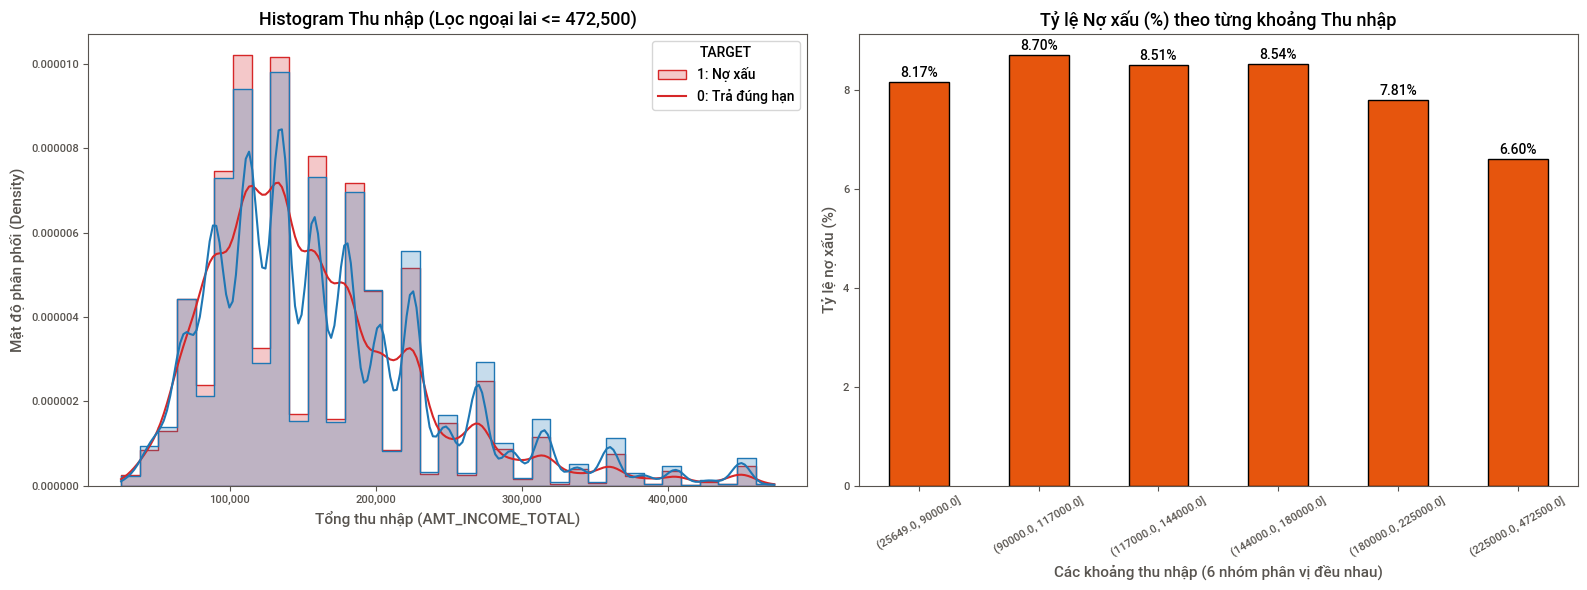

In [10]:
# Vẽ Biểu đồ Histogram giữa "AMT_INCOME_TOTAL" và "TARGET" để thấy được mối quan hệ giữa hai features này. 
income_cutoff = df_train['AMT_INCOME_TOTAL'].quantile(0.99)
df_filtered = df_train[df_train['AMT_INCOME_TOTAL'] <= income_cutoff].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))


sns.histplot(
    data=df_filtered,
    x='AMT_INCOME_TOTAL',
    hue='TARGET',
    bins=35,
    kde=True,
    stat='density',        
    common_norm=False,
    palette={0: '#1f77b4', 1: '#d62728'},
    element='step',
    ax=axes[0]
)
axes[0].set_title(f"Histogram Thu nhập (Lọc ngoại lai <= {income_cutoff:,.0f})", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Tổng thu nhập (AMT_INCOME_TOTAL)", fontsize=11)
axes[0].set_ylabel("Mật độ phân phối (Density)", fontsize=11)
axes[0].legend(title="TARGET", labels=["1: Nợ xấu", "0: Trả đúng hạn"])
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x):,}'))

df_filtered['INCOME_BIN'] = pd.qcut(df_filtered['AMT_INCOME_TOTAL'], q=6, precision=0)
default_rate = df_filtered.groupby('INCOME_BIN', observed=False)['TARGET'].mean() * 100

default_rate.plot(
    kind='bar',
    color='#e6550d',
    edgecolor='black',
    ax=axes[1]
)
axes[1].set_title("Tỷ lệ Nợ xấu (%) theo từng khoảng Thu nhập", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Các khoảng thu nhập (6 nhóm phân vị đều nhau)", fontsize=11)
axes[1].set_ylabel("Tỷ lệ nợ xấu (%)", fontsize=11)
axes[1].tick_params(axis='x', rotation=30)

# Hiển thị số liệu % trực tiếp trên từng cột
for i, val in enumerate(default_rate):
    axes[1].text(i, val + 0.1, f"{val:.2f}%", ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

### Quan sát chính ở các nhóm biến

**Điểm tín dụng ngoài & Tài chính**
- `TARGET`: tỷ lệ nợ xấu toàn tập là ~8.07% (mất cân bằng rõ).
- `EXT_SOURCE_1 / 2 / 3`: điểm chuẩn hóa trong `(0, 1)`, thiếu lần lượt 56.38%, 0.21% và 19.83%. Giá trị càng thấp tỷ lệ nợ xấu càng cao.
  -> Suy ra: có thể gộp thêm đặc trưng trung bình `EXT_SOURCES_MEAN` và giữ riêng nhóm missing cho `EXT_SOURCE_1/3` thay vì điền `0.0`.
- `AMT_INCOME_TOTAL`: lệch phải mạnh (đa số dưới 300k). Nhóm thu nhập từ 300k trở lên có tỷ lệ nợ xấu thấp hơn phần còn lại.
- `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_GOODS_PRICE`: phản ánh quy mô khoản vay và áp lực trả góp định kỳ.
  -> Suy ra: nên tạo thêm các tỷ số `PAYMENT_RATE = AMT_ANNUITY / AMT_CREDIT`, `INCOME_CREDIT_PERC = AMT_INCOME_TOTAL / AMT_CREDIT`, `ANNUITY_INCOME_PERC = AMT_ANNUITY / AMT_INCOME_TOTAL`.

**Nhân khẩu học**
- `DAYS_BIRTH`: lưu dạng số ngày âm (-25,229 đến -7,489 ngày, tức ~20–69 tuổi). Nhóm 20–30 tuổi có tỷ lệ nợ xấu 11.46%, giảm dần xuống 4.92% ở nhóm 60–70 tuổi.
  -> Suy ra: người trẻ thường chưa ổn định tài chính nên rủi ro cao hơn. Cần đổi sang `AGE = -DAYS_BIRTH / 365`.
- `CODE_GENDER`: nam giới có tỷ lệ nợ xấu 10.14%, cao hơn nữ giới (7.00%); có 4 mẫu `XNA`.
- `NAME_EDUCATION_TYPE`: tỷ lệ nợ xấu giảm dần theo học vấn (Lower secondary 10.93% $\to$ Secondary 8.94% $\to$ Higher education 5.36% $\to$ Academic degree 1.83%).
- `NAME_FAMILY_STATUS` & `CNT_CHILDREN`: nhóm độc thân/sống thử có tỷ lệ nợ xấu ~9.8–9.9%, cao hơn nhóm đã kết hôn (7.56%) và góa (5.82%). Gia đình đông con (4–5+) có tỷ lệ nợ xấu >10%.

**Việc làm & Nơi ở**
- `DAYS_EMPLOYED`: có **55,374 dòng (18.01%)** mang giá trị `365243` (mã quy ước cho người nghỉ hưu/không đi làm, nợ xấu chỉ 5.40% so với 8.66% ở nhóm đang làm việc) và 2 dòng bằng `0`.
  -> Hướng xử lý: tách cờ `DAYS_EMPLOYED_ANOM = (DAYS_EMPLOYED == 365243)`, chuyển `365243` về `NaN` rồi tính `YEARS_EMPLOYED` (giữ `0.0` dương khi bằng `0`).
- `OCCUPATION_TYPE`: thiếu 31.35% (hơn 96k dòng); nhóm lao động phổ thông (17.15%) và tài xế (11.33%) rủi ro cao hơn hẳn kế toán (4.83%) hay quản lý (6.22%).
  -> Hướng xử lý: gán giá trị thiếu thành `"Missing"` thay vì xóa dòng.
- `NAME_HOUSING_TYPE`, `FLAG_OWN_CAR`, `FLAG_OWN_REALTY`: người thuê nhà (12.31%) hoặc ở cùng bố mẹ (11.70%) có rủi ro cao hơn người sở hữu nhà riêng (7.80%); người có ô tô/bất động sản có tỷ lệ nợ xấu thấp hơn.

## 3. Kiểm định thống kê trên 26 đặc trưng sau làm sạch

Chạy `engineer_features` để xử lý `365243` và tạo 5 biến mới thành `26` đặc trưng, sau đó thực hiện `ks_2samp` (16 biến số) và `chi2_contingency` + Cramér's V (10 biến danh mục) kèm hiệu chỉnh đa kiểm định Benjamini-Hochberg (`p_adj`).

In [11]:
df_clean_eda = engineer_features(df_train, validate=False, keep_target=True)

ks_table = compute_ks_tests(df_clean_eda, NUMERICAL_COLS, target_col=TARGET_COL)
chi2_table = compute_chi2_tests(df_clean_eda, CATEGORICAL_COLS, target_col=TARGET_COL)
unified_stats = summarize_statistical_tests(df_clean_eda, NUMERICAL_COLS, CATEGORICAL_COLS, target_col=TARGET_COL)

print("=== KIỂM ĐỊNH KS (16 BIẾN SỐ) ===")
display(
    ks_table[
        ["feature", "stat", "p_value", "p_adj", "significant", "missing_rate_%", "missing_good_%", "missing_bad_%", "median_good", "median_bad"]
    ].round({"stat": 4, "missing_rate_%": 2, "missing_good_%": 2, "missing_bad_%": 2, "median_good": 4, "median_bad": 4})
)

print("\n=== KIỂM ĐỊNH CHI-SQUARE & CRAMÉR'S V (10 BIẾN DANH MỤC) ===")
display(
    chi2_table[
        ["feature", "stat", "cramers_v", "dof", "min_expected_freq", "p_value", "p_adj", "significant", "missing_rate_%"]
    ].round({"stat": 2, "cramers_v": 4, "min_expected_freq": 1, "missing_rate_%": 2})
)

print("\n=== BẢNG TỔNG HỢP (feature | stat | p_value | significant) ===")
display(
    unified_stats[["feature", "test_type", "stat", "effect_size", "p_value", "p_adj", "significant"]]
    .round({"stat": 4, "effect_size": 4})
)

=== KIỂM ĐỊNH KS (16 BIẾN SỐ) ===


,feature,stat,p_value,p_adj,significant,missing_rate_%,missing_good_%,missing_bad_%,median_good,median_bad
0,EXT_SOURCES_MEAN,0.3241,0.000000e+00,0.000000e+00,True,0.06,0.06,0.06,0.5338,0.3991
1,EXT_SOURCE_3,0.2698,0.000000e+00,0.000000e+00,True,19.83,19.56,22.87,0.5460,0.3791
2,EXT_SOURCE_1,0.2427,0.000000e+00,0.000000e+00,True,56.38,56.11,59.50,0.5175,0.3617
3,EXT_SOURCE_2,0.2237,0.000000e+00,0.000000e+00,True,0.21,0.22,0.21,0.5739,0.4404
4,YEARS_EMPLOYED,0.1320,2.047049e-303,6.550555e-303,True,18.01,18.53,12.04,4.6329,3.3699
5,AGE,0.1219,7.355860e-296,1.961563e-295,True,0.00,0.00,0.00,43.4986,39.1288
6,PAYMENT_RATE,0.0946,3.434224e-178,7.849656e-178,True,0.00,0.00,0.00,0.0500,0.0500
7,AMT_GOODS_PRICE,0.0942,1.095322e-176,2.190645e-176,True,0.09,0.09,0.08,450000.0000,450000.0000
8,AMT_CREDIT,0.0695,3.316027e-96,5.895159e-96,True,0.00,0.00,0.00,517788.0000,497520.0000
9,DAYS_EMPLOYED_ANOM,0.0649,6.371102e-84,1.019376e-83,True,0.00,0.00,0.00,0.0000,0.0000



=== KIỂM ĐỊNH CHI-SQUARE & CRAMÉR'S V (10 BIẾN DANH MỤC) ===


,feature,stat,cramers_v,dof,min_expected_freq,p_value,p_adj,significant,missing_rate_%
0,OCCUPATION_TYPE,1975.08,0.0801,18,42.5,0.000000e+00,0.000000e+00,True,31.35
1,ORGANIZATION_TYPE,1595.90,0.0720,48,25.6,6.326063e-303,3.163032e-302,True,0.00
2,NAME_INCOME_TYPE,1227.99,0.0632,4,4.4,1.361579e-264,4.538598e-264,True,0.00
3,NAME_EDUCATION_TYPE,1019.21,0.0576,4,13.2,2.447681e-219,6.119203e-219,True,0.00
4,CODE_GENDER,920.79,0.0547,2,0.3,1.129022e-200,2.258044e-200,True,0.00
5,NAME_FAMILY_STATUS,504.69,0.0405,5,0.2,7.744842e-107,1.290807e-106,True,0.00
6,NAME_HOUSING_TYPE,420.56,0.0370,5,90.6,1.099089e-88,1.570127e-88,True,0.00
7,NAME_CONTRACT_TYPE,293.15,0.0309,1,2363.7,1.023515e-65,1.279394e-65,True,0.00
8,FLAG_OWN_CAR,146.66,0.0218,1,8443.2,9.330994e-34,1.036777e-33,True,0.00
9,FLAG_OWN_REALTY,11.58,0.0061,1,7604.6,6.681470e-04,6.681470e-04,True,0.00



=== BẢNG TỔNG HỢP (feature | stat | p_value | significant) ===


,feature,test_type,stat,effect_size,p_value,p_adj,significant
0,EXT_SOURCES_MEAN,KS (2-sample),0.3241,0.3241,0.000000e+00,0.000000e+00,True
1,EXT_SOURCE_3,KS (2-sample),0.2698,0.2698,0.000000e+00,0.000000e+00,True
2,EXT_SOURCE_1,KS (2-sample),0.2427,0.2427,0.000000e+00,0.000000e+00,True
3,EXT_SOURCE_2,KS (2-sample),0.2237,0.2237,0.000000e+00,0.000000e+00,True
4,YEARS_EMPLOYED,KS (2-sample),0.1320,0.1320,2.047049e-303,8.870544e-303,True
5,AGE,KS (2-sample),0.1219,0.1219,7.355860e-296,2.390655e-295,True
6,PAYMENT_RATE,KS (2-sample),0.0946,0.0946,3.434224e-178,7.440820e-178,True
7,AMT_GOODS_PRICE,KS (2-sample),0.0942,0.0942,1.095322e-176,2.190645e-176,True
8,OCCUPATION_TYPE,Chi-square,1975.0828,0.0801,0.000000e+00,0.000000e+00,True
9,ORGANIZATION_TYPE,Chi-square,1595.8963,0.0720,6.326063e-303,2.349681e-302,True


### Ghi chú từ bảng kiểm định
- Với $N = 307,511$, gần như toàn bộ biến đều có $p_{\text{adj}} < 0.05$, nên cần xét thêm **Effect Size** (`KS` và `Cramér's V`) để đánh giá độ tách thực tế thay vì chỉ nhìn p-value.
- Nhóm điểm ngoài (`EXT_SOURCES_MEAN`, `EXT_SOURCE_2/3/1`) và `AGE`, `YEARS_EMPLOYED` (sau khi tách `365243`) đứng đầu về `KS` ($0.10 - 0.30$); `OCCUPATION_TYPE`, `NAME_INCOME_TYPE`, `NAME_EDUCATION_TYPE` dẫn đầu về `Cramér's V`.
- Tỷ lệ missing ở `EXT_SOURCE_1` và `OCCUPATION_TYPE` lệch nhau giữa 2 nhóm `TARGET=0/1` $\to$ suy ra cần giữ `"Missing"` như một nhóm/cờ riêng.

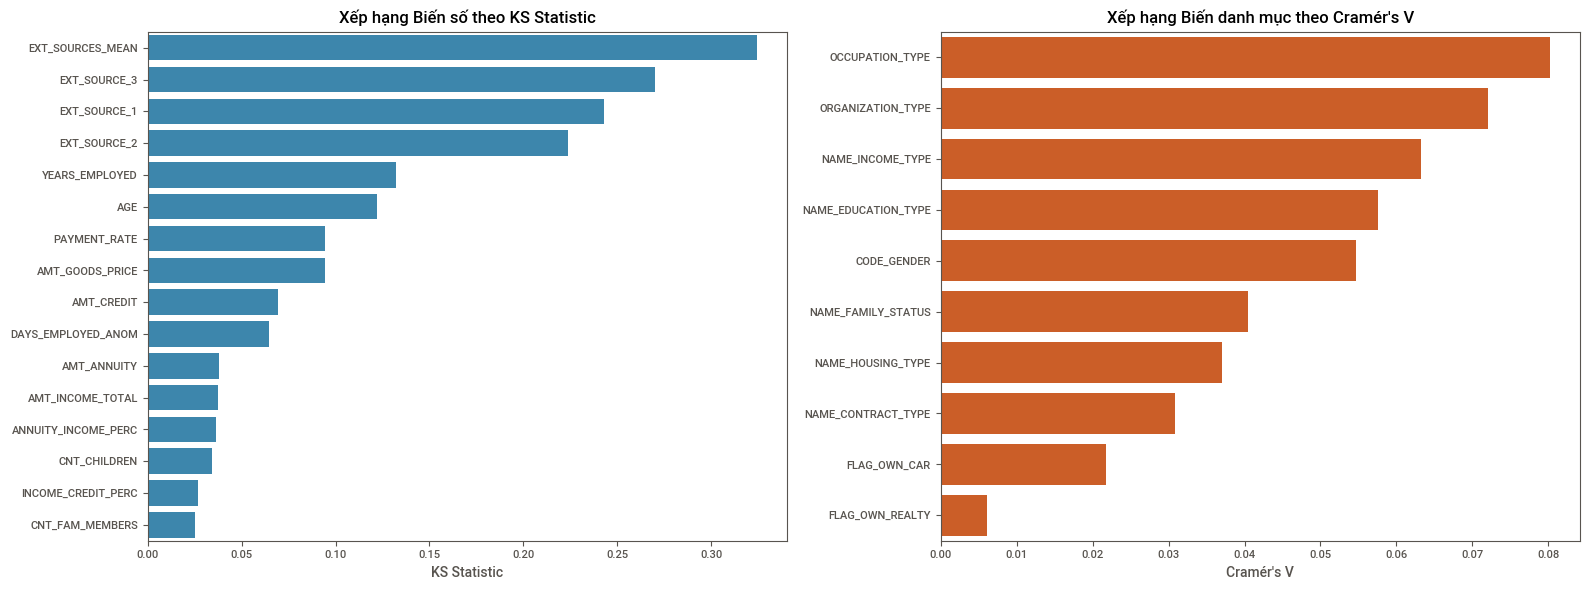

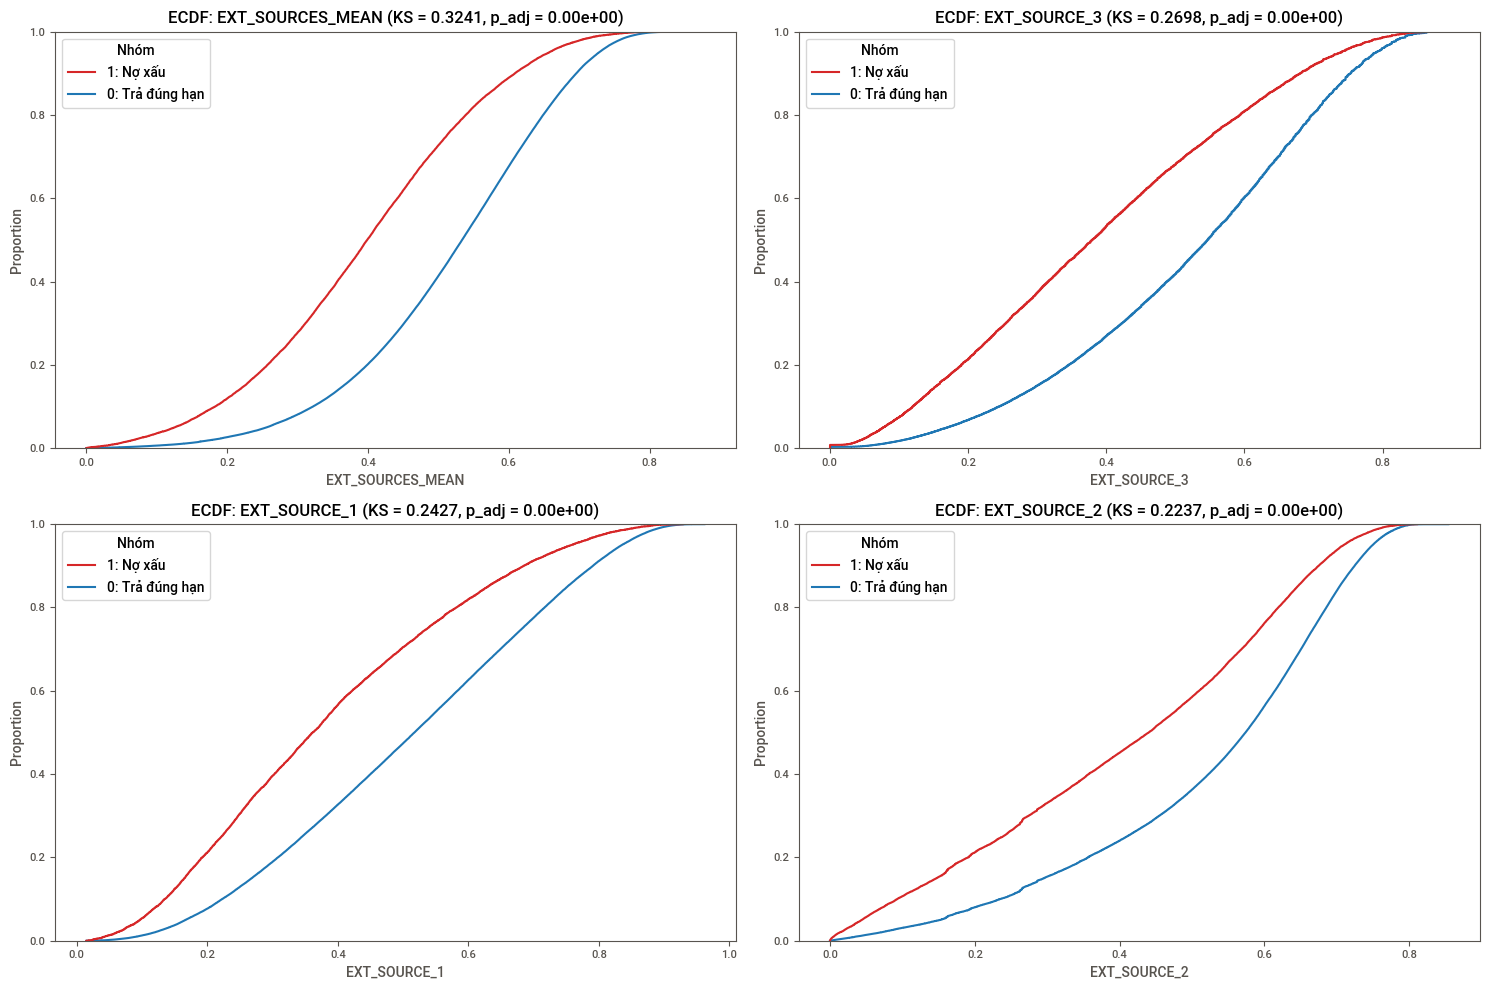

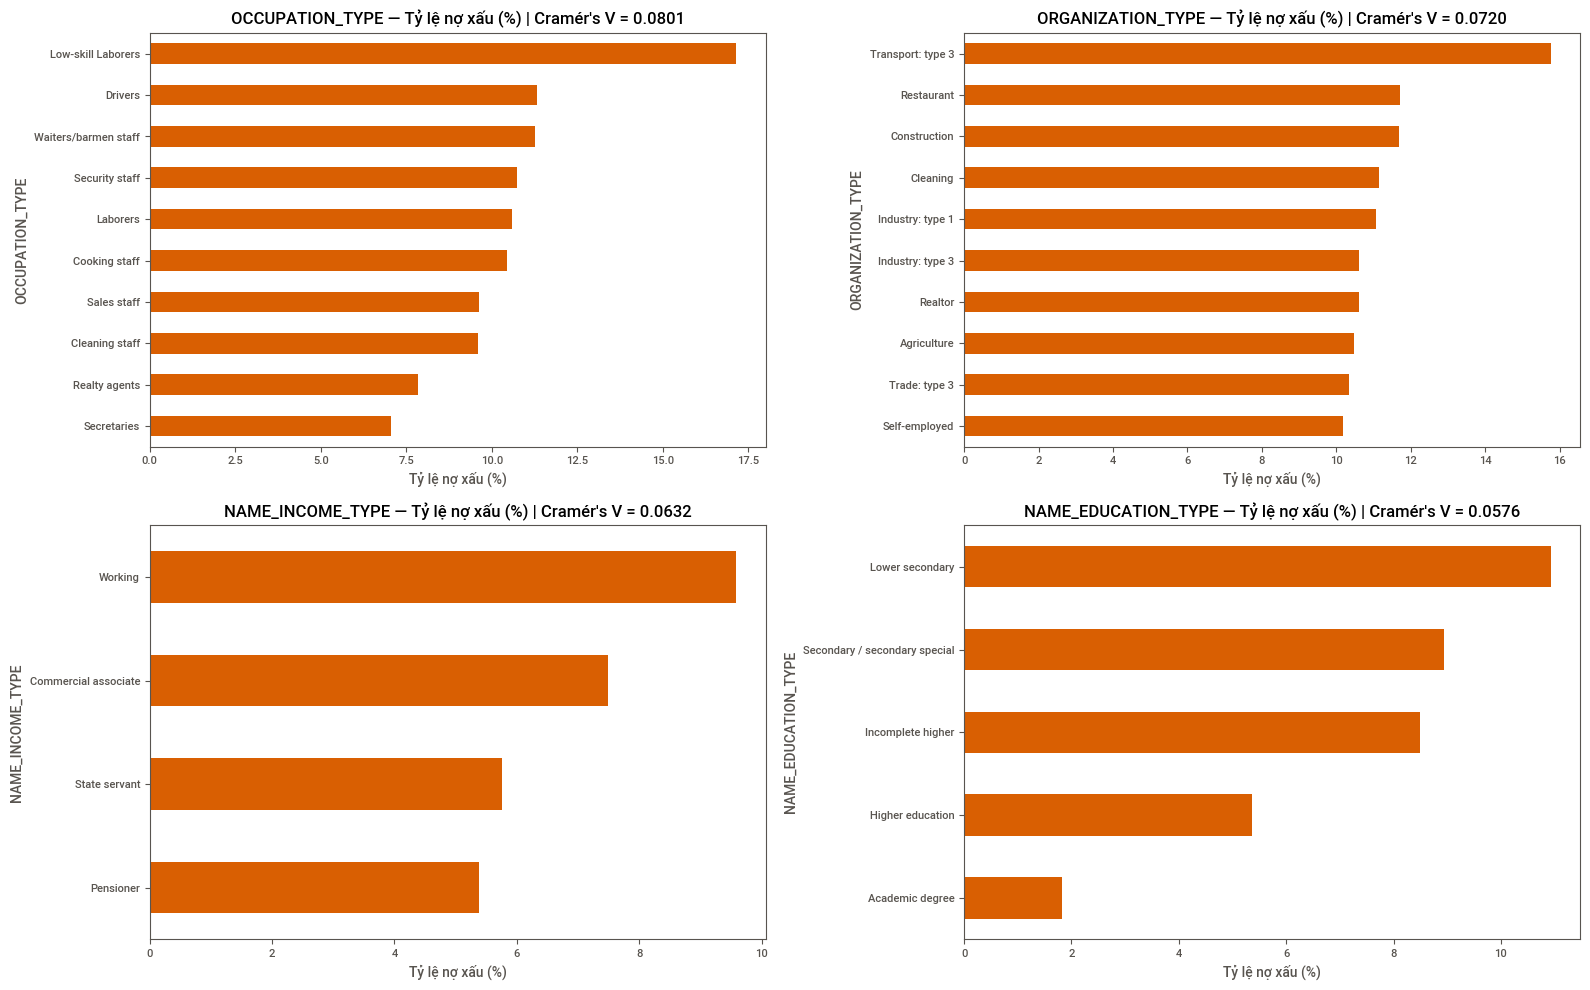

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=ks_table, y="feature", x="stat", color="#2b8cbe", ax=axes[0])
axes[0].set_title("Xếp hạng Biến số theo KS Statistic", fontweight="bold")
axes[0].set_xlabel("KS Statistic")
axes[0].set_ylabel("")

sns.barplot(data=chi2_table, y="feature", x="cramers_v", color="#e6550d", ax=axes[1])
axes[1].set_title("Xếp hạng Biến danh mục theo Cramér's V", fontweight="bold")
axes[1].set_xlabel("Cramér's V")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

top4_num = ks_table["feature"].head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes.ravel(), top4_num):
    row_info = ks_table.loc[ks_table["feature"] == col].iloc[0]
    df_ecdf = df_clean_eda[[col, TARGET_COL]].dropna().copy()
    df_ecdf["Nhóm"] = df_ecdf[TARGET_COL].map({0: "0: Trả đúng hạn", 1: "1: Nợ xấu"})
    sns.ecdfplot(
        data=df_ecdf,
        x=col,
        hue="Nhóm",
        palette={"0: Trả đúng hạn": "#1f77b4", "1: Nợ xấu": "#d62728"},
        ax=ax,
    )
    ax.set_title(
        f"ECDF: {col} (KS = {row_info['stat']:.4f}, p_adj = {row_info['p_adj']:.2e})",
        fontweight="bold",
    )
plt.tight_layout()
plt.show()

top4_cat = chi2_table["feature"].head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, col in zip(axes.ravel(), top4_cat):
    row_info = chi2_table.loc[chi2_table["feature"] == col].iloc[0]
    tmp = df_clean_eda[[col, TARGET_COL]].copy()
    tmp[col] = tmp[col].fillna("Missing")
    rates = tmp.groupby(col, observed=False)[TARGET_COL].agg(["mean", "count"]).sort_values("mean", ascending=False)
    rates = rates[rates["count"] >= 100].head(10)
    (rates["mean"] * 100).plot(kind="barh", color="#d95f02", ax=ax)
    ax.invert_yaxis()
    ax.set_title(
        f"{col} — Tỷ lệ nợ xấu (%) | Cramér's V = {row_info['cramers_v']:.4f}",
        fontweight="bold",
    )
    ax.set_xlabel("Tỷ lệ nợ xấu (%)")
plt.tight_layout()
plt.show()

### Quan sát trực quan
- Trên đồ thị ECDF, khoảng cách dọc lớn nhất giữa hai đường phản ánh đúng `KS`: nhóm vỡ nợ dồn nhiều về vùng `EXT_SOURCE` thấp và độ tuổi trẻ hơn.
- Các biến danh mục top đầu (`OCCUPATION_TYPE`, `NAME_INCOME_TYPE`, `NAME_EDUCATION_TYPE`, `CODE_GENDER`) đều thể hiện độ chênh tỷ lệ nợ xấu rõ giữa các phân nhóm.

## 4. Đánh giá WoE & IV trên tập Train 

Để tránh rò rỉ nhãn từ tập `valid` và `test`, `WoEEncoder` chỉ được `fit` trên tập `data/processed/train.csv` (`249,083` dòng).

Số đặc trưng đạt IV >= 0.02 (Tree Binning): 17 / 26


,feature,feature_type,n_bins,iv_tree,iv_strength,is_monotonic,selected,iv_quantile
0,EXT_SOURCES_MEAN,numerical,7,0.6052,Suspicious (>0.50),True,True,0.5905
1,EXT_SOURCE_3,numerical,7,0.3292,Strong (0.30-0.50),True,True,0.3145
2,EXT_SOURCE_2,numerical,7,0.3167,Strong (0.30-0.50),True,True,0.2925
3,EXT_SOURCE_1,numerical,7,0.1554,Medium (0.10-0.30),True,True,0.1470
4,PAYMENT_RATE,numerical,7,0.1315,Medium (0.10-0.30),False,True,0.0265
5,YEARS_EMPLOYED,numerical,7,0.1149,Medium (0.10-0.30),True,True,0.1108
6,AGE,numerical,6,0.0861,Weak (0.02-0.10),True,True,0.0833
7,OCCUPATION_TYPE,categorical,13,0.0749,Weak (0.02-0.10),None,True,0.0749
8,AMT_GOODS_PRICE,numerical,7,0.0681,Weak (0.02-0.10),False,True,0.0798
9,NAME_INCOME_TYPE,categorical,5,0.0579,Weak (0.02-0.10),None,True,0.0579


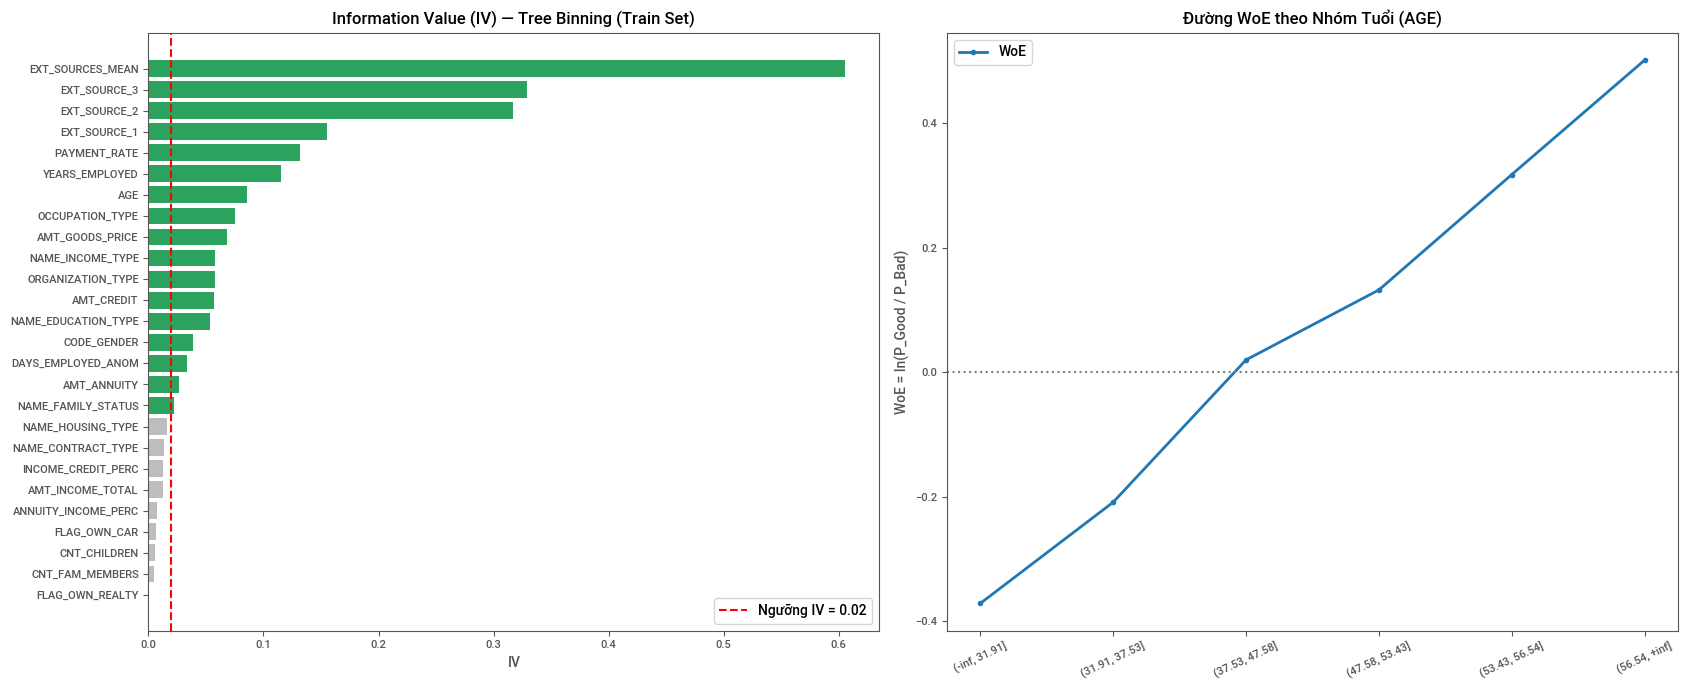


--- Chi tiết bảng WoE của PAYMENT_RATE (Tree Binning) ---


,bin,total,bad,good,event_rate,dist_good,dist_bad,woe,iv_contrib
0,"(-inf, 0.03183]",36398,2114,34284,0.0581,0.1497,0.1051,0.3535,0.0158
1,"(0.03183, 0.03913]",36379,2865,33514,0.0788,0.1464,0.1425,0.0269,0.0001
2,"(0.03913, 0.0466]",28002,1390,26612,0.0496,0.1162,0.0691,0.5194,0.0245
3,"(0.0466, 0.04973]",21026,3125,17901,0.1486,0.0782,0.1554,-0.6870,0.0531
4,"(0.04973, 0.09252]",100491,9349,91142,0.0930,0.3980,0.4649,-0.1552,0.0104
5,"(0.09252, +inf]",26777,1265,25512,0.0472,0.1114,0.0629,0.5714,0.0277
6,Missing,10,0,10,0.0000,0.0000,0.0000,0.6122,0.0000


In [13]:
df_train_split = pd.read_csv(DATA_PROCESSED_DIR / "train.csv")
X_tr = df_train_split.drop(columns=[TARGET_COL])
y_tr = df_train_split[TARGET_COL]

woe_tree = WoEEncoder(binning="tree", iv_threshold=0.02).fit(X_tr, y_tr)
woe_quant = WoEEncoder(binning="quantile", iv_threshold=0.02).fit(X_tr, y_tr)

iv_compare = woe_tree.get_iv_summary().merge(
    woe_quant.get_iv_summary()[["feature", "iv"]].rename(columns={"iv": "iv_quantile"}),
    on="feature",
    how="left",
).rename(columns={"iv": "iv_tree"})

print(f"Số đặc trưng đạt IV >= 0.02 (Tree Binning): {len(woe_tree.selected_features_)} / {len(iv_compare)}")
display(iv_compare.round({"iv_tree": 4, "iv_quantile": 4}))

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
plot_iv = iv_compare.sort_values("iv_tree", ascending=True)
colors = ["#2ca25f" if v >= 0.02 else "#bdbdbd" for v in plot_iv["iv_tree"]]
axes[0].barh(plot_iv["feature"], plot_iv["iv_tree"], color=colors)
axes[0].axvline(0.02, color="red", linestyle="--", linewidth=1.5, label="Ngưỡng IV = 0.02")
axes[0].set_title("Information Value (IV) — Tree Binning (Train Set)", fontweight="bold")
axes[0].set_xlabel("IV")
axes[0].legend()

age_tbl = woe_tree.get_woe_table("AGE")
axes[1].plot(age_tbl["bin"], age_tbl["woe"], marker="o", linewidth=2, color="#1f77b4", label="WoE")
axes[1].axhline(0, color="gray", linestyle=":")
axes[1].set_title("Đường WoE theo Nhóm Tuổi (AGE)", fontweight="bold")
axes[1].set_ylabel("WoE = ln(P_Good / P_Bad)")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend()

plt.tight_layout()
plt.show()

print("\n--- Chi tiết bảng WoE của PAYMENT_RATE (Tree Binning) ---")
display(woe_tree.get_woe_table("PAYMENT_RATE").round({"event_rate": 4, "dist_good": 4, "dist_bad": 4, "woe": 4, "iv_contrib": 4}))

### Tổng kết
- **Sàng lọc & Kiểm định:** Hoàn thành quét `120` cột thô bằng `screen_raw_features`, chọn `21` cột thô -> `26` đặc trưng sạch, kiểm chứng bằng `ks_2samp` và `chi2_contingency` + `Cramér's V`.
- **Tiền xử lý chuẩn hóa:** Đóng gói sạch anomaly `365243`, guard chia `0` và `TabularPreprocessor` trong [src/preprocess.py], tạo 3 split `train/valid/test`.
- **WoE & IV (`17 / 26` biến đạt `IV >= 0.02`):** `EXT_SOURCES_MEAN` có `IV = 0.6052` (do tổng hợp 3 nguồn điểm ngoài, không phải leakage), `EXT_SOURCE_3/2/1` và `YEARS_EMPLOYED`, `AGE` đều đơn điệu hoàn hảo; **Tree binning** giúp `PAYMENT_RATE` đạt `IV = 0.1315` (so với `0.0265` ở Quantile binning).
- **Hướng đi tiếp ở Ngày 2:** Dùng `17` biến WoE để train **Logistic Regression Scorecard** và dùng cả `26` biến cho **LightGBM** (để tận dụng tương tác phi tuyến), sau đó thực hiện Probability Calibration và giải thích bằng SHAP.